# v13: Wu, population betas only (no y in the gradient), Kev 800M

In [1]:
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

# The `beta_ols`, `beta_train` and `beta_population` packages are in `src/` next to this notebook
EXPLORATION_DIR = CODE_DIR / "papers" / "beta-loss" / "exploration"
SRC_DIR = EXPLORATION_DIR / "src"
if not (SRC_DIR / "beta_population").is_dir():
    raise RuntimeError(f"`beta_population` package not found in {SRC_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and `src/` on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_population.config import PopulationTrainConfig
from beta_population.trainer import load_population_run, run_population_training
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import set_checkpointing, snapshot_trainable
from beta_train.trainer import load_run, run_training
from beta_train.validation import PopulationValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to train jaredpalmer/kev-0.8b in bf16")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-4b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0
# Recompute activations in backward (less VRAM, slower). Memory-only: not part of a run's identity
GRADIENT_CHECKPOINTING = False

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
set_checkpointing(kev_model, GRADIENT_CHECKPOINTING)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "gradient_checkpointing": GRADIENT_CHECKPOINTING,
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run and the step-0 validation start from them
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-4b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"131,170,816"
total_params,"4,336,922,112"
gradient_checkpointing,False
model_load_sec,2.551


Snapshotted 500 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# Wu is the training dataset (its inputs; its y only through the population betas below) and also a validator
# (in-sample: does beta-only training reduce Wu's population beta error?). Kriner and Grummon 2025 are held out.
ITEM_DATASETS = [         # training items are built for these
    "wu2025",
    # "berke2023",
]
VALIDATION_DATASETS = [   # validation runs on these
    "wu2025",
    "kriner2026",
    "grummon2025",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Wu has one task variable, so its training piece is the whole dataset under its own name.
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")

wu2025: 1,861 respondents | 18,591 tasks | 1 regression(s)


wu2025                 
                                              beta      se std_beta
Monthly bill: $110 vs $105                 -0.0969  0.0078  -0.1938
Monthly bill: $115 vs $105                 -0.1779  0.0084  -0.3559
Monthly bill: $120 vs $105                 -0.2894  0.0092  -0.5789
Monthly bill: $125 vs $105                 -0.3832  0.0100  -0.7664
Percentage of renewables: 30% vs 10%        0.0973  0.0073   0.1946
Percentage of renewables: 50% vs 10%        0.1706  0.0081   0.3413
Percentage of renewables: 100% vs 10%       0.2421  0.0096   0.4842
Locally produced renewables: Yes vs No      0.1042  0.0056   0.2085
sigma_y                                     0.5000     NaN      NaN
n_rows                                  37182.0000     NaN      NaN

kriner2026: 1,000 respondents | 5,000 tasks | 1 regression(s)


kriner2026                 
                                       beta      se std_beta
Airline: Frontier                   -0.0854  0.0137  -0.1709
Airline: Southwest                  -0.0238  0.0139  -0.0476
Airline: United                     -0.0220  0.0132  -0.0440
Fuel: Sustainable aviation fuel      0.0691  0.0105   0.1381
Baggage: Checked bag+carry-on        0.0561  0.0124   0.1121
Baggage: Personal item only         -0.1393  0.0122  -0.2785
Space: Extra legroom                 0.0653  0.0097   0.1305
Seat: Middle                        -0.0906  0.0127  -0.1813
Seat: Window                         0.0384  0.0124   0.0769
Price: $275                         -0.0853  0.0137  -0.1705
Price: $300                         -0.1953  0.0142  -0.3907
Price: $325                         -0.3040  0.0143  -0.6080
sigma_y                              0.5000     NaN      NaN
n_rows                           10000.0000     NaN      NaN

grummon2025: 5,633 respondents | 33,798 tasks | 1 regression(s)


grummon2025                 
                                          beta      se std_beta
NutritionInfo vs Positive               0.1844  0.0119   0.4196
HighIn vs Positive                      0.0541  0.0122   0.1231
Positive+NutritionInfo vs Positive      0.1788  0.0120   0.4069
Positive+HighIn vs Positive             0.1194  0.0122   0.2718
Spectrum vs Positive                    0.1083  0.0125   0.2464
sigma_y                                 0.4395     NaN      NaN
n_rows                              33798.0000     NaN      NaN

TRAIN_DATASETS = ['wu2025']


# Training targets: the population betas (published-table stand-in)

In [4]:
# One target vector per training dataset and regression: the standardized human population betas (beta / sigma),
# in the spec's target order. This table is the only thing training sees of the respondents' choices.
target_std_betas_by_dataset = {}
for dataset_name in TRAIN_DATASETS:
    dataset_ols = human_ols_by_dataset[dataset_name]
    dataset_targets = {}
    for group, spec in regression_specs_by_dataset[dataset_name].items():
        group_ols = dataset_ols[dataset_ols["model"] == group].set_index("term")
        target_values = group_ols.loc[spec.target_labels, "std_beta"].to_numpy(dtype=np.float64)
        dataset_targets[group] = torch.tensor(target_values, dtype=torch.float64)
    target_std_betas_by_dataset[dataset_name] = dataset_targets

for dataset_name, dataset_targets in target_std_betas_by_dataset.items():
    for group, target in dataset_targets.items():
        labels = regression_specs_by_dataset[dataset_name][group].target_labels
        display(pd.Series(target.numpy(), index=labels, name=f"{dataset_name} | {group} target std beta").round(4).to_frame())

,wu2025 | wu2025 target std beta
Monthly bill: $110 vs $105,-0.1938
Monthly bill: $115 vs $105,-0.3559
Monthly bill: $120 vs $105,-0.5789
Monthly bill: $125 vs $105,-0.7664
Percentage of renewables: 30% vs 10%,0.1946
Percentage of renewables: 50% vs 10%,0.3413
Percentage of renewables: 100% vs 10%,0.4842
Locally produced renewables: Yes vs No,0.2085


# Validators and training items

In [5]:
# One fused validator per VALIDATION_DATASETS entry (population OLS from the dataset's module)
# Per-GPU-batch inference budgets: lower them if validation runs out of memory, raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000

validators = {}
for dataset_name in VALIDATION_DATASETS:
    validators[dataset_name] = PopulationValidator(
        beta_ols.DATASET_MODULES[dataset_name],
        choice_dfs[dataset_name],
        regression_specs_by_dataset[dataset_name],
        max_questions=VALIDATION_MAX_QUESTIONS,
        max_chars=VALIDATION_MAX_CHARS,
    )
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,graph_limits,prep_sec
validator,,,,,,,,
wu2025,fused,18591,1831,wu2025,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",2.823
kriner2026,fused,5000,990,kriner2026,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",0.800
grummon2025,fused,33798,4906,grummon2025,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",6.395


In [6]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

,source
validator,
wu2025,computed
kriner2026,cache
grummon2025,cache


,wu2025,kriner2026,grummon2025
kl_loss,0.8930,0.8107,1.0998
beta_mse,0.0236,0.0041,0.0211
beta_mae,0.1164,0.0513,0.1233
beta_mape_pct,58.6923,63.9489,146.0585
spearman_rho,0.9762,0.8951,0.8000
eval_prep_sec,3.4667,0.0542,0.5373
eval_gpu_sec,158.4898,38.2256,313.7828
eval_wall_sec,165.3385,40.5354,317.6025
eval_ms_per_task,8.8935,8.1071,9.3971


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Monthly bill: $110 vs $105,wu2025,-0.0969,-0.0163,0.0807,0.0807
Monthly bill: $115 vs $105,wu2025,-0.1779,-0.0420,0.1360,0.1360
Monthly bill: $120 vs $105,wu2025,-0.2894,-0.0561,0.2333,0.2333
Monthly bill: $125 vs $105,wu2025,-0.3832,-0.0778,0.3054,0.3054
Percentage of renewables: 30% vs 10%,wu2025,0.0973,0.1055,0.0082,0.0082
Percentage of renewables: 50% vs 10%,wu2025,0.1706,0.2210,0.0504,0.0504
Percentage of renewables: 100% vs 10%,wu2025,0.2421,0.2443,0.0022,0.0022
Locally produced renewables: Yes vs No,wu2025,0.1042,-0.0112,-0.1154,0.1154


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Airline: Frontier,kriner2026,-0.0854,-0.1804,-0.0950,0.0950
Airline: Southwest,kriner2026,-0.0238,0.0220,0.0458,0.0458
Airline: United,kriner2026,-0.0220,-0.0166,0.0054,0.0054
Fuel: Sustainable aviation fuel,kriner2026,0.0691,0.0995,0.0305,0.0305
Baggage: Checked bag+carry-on,kriner2026,0.0561,0.0877,0.0316,0.0316
Baggage: Personal item only,kriner2026,-0.1393,-0.1861,-0.0468,0.0468
Space: Extra legroom,kriner2026,0.0653,0.1244,0.0592,0.0592
Seat: Middle,kriner2026,-0.0906,-0.0841,0.0065,0.0065
Seat: Window,kriner2026,0.0384,0.0087,-0.0297,0.0297


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
NutritionInfo vs Positive,grummon2025,0.1844,0.2495,0.0651,0.0651
HighIn vs Positive,grummon2025,0.0541,-0.2079,-0.2620,0.2620
Positive+NutritionInfo vs Positive,grummon2025,0.1788,0.3053,0.1265,0.1265
Positive+HighIn vs Positive,grummon2025,0.1194,-0.0016,-0.1211,0.1211
Spectrum vs Positive,grummon2025,0.1083,0.0665,-0.0418,0.0418


In [8]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were
# already built for this data, tokenizer, and code
item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

,items (rows),source
dataset,,
wu2025,18591,cache


,items (rows),respondents,regression_groups
dataset,,,
wu2025,18591,1861,wu2025


# Find max micro chunk

In [9]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) Wu chunks
SEARCH_GRADIENT_CHECKPOINTING = GRADIENT_CHECKPOINTING   # search with the setting you train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

[W1117 21:43:48.682198912 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 27262976 bytes (free: 24510464, total: 33733804032).
[W1117 21:43:48.682317642 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 27262976 bytes (free: 24510464, total: 33733804032).
[W1117 21:43:59.719131736 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 2097152 bytes (free: 5636096, total: 33733804032).
[W1117 21:44:01.509767075 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 2097152 bytes (free: 5636096, total: 33733804032).


,chunk_size,dataset,rule,padded_tokens,fits,peak_gib,peak_pct_of_vram
0,1,wu2025,most padded tokens each,372,True,11.73,37.3
1,1,wu2025,longest state + longest branch + most questions,371,True,11.74,37.4
2,1,wu2025,longest branch + most questions,368,True,11.72,37.3
3,2,wu2025,longest state + longest branch + most questions,750,True,14.78,47.0
4,2,wu2025,most padded tokens each,744,True,14.72,46.9
5,2,wu2025,longest state + most questions,742,True,14.73,46.9
6,4,wu2025,longest state + longest branch + most questions,1500,True,20.75,66.0
7,4,wu2025,most padded tokens each,1488,True,20.64,65.7
8,4,wu2025,longest state + most questions,1484,True,20.61,65.6
9,6,wu2025,longest state + longest branch + most questions,2250,True,26.47,84.2


gradient_checkpointing=False | MAX_FITTING_MICRO_CHUNK = 7


# Train

In [10]:
MAX_FITTING_MICRO_CHUNK = 5
GRADIENT_CHECKPOINTING

False

In [11]:
# Run folders: one per run under RUNS_DIR (stats, betas per validation, checkpoints/best.pt, checkpoints/last.pt)
NOTEBOOK = "train-beta-v13-wu-beta-only-4b"
RUNS_DIR = EXPLORATION_DIR / "runs" / NOTEBOOK
# ONE validator's column picks checkpoints/best.pt. Both runs below use the same rule, so the beta-only run and the
# KL-only control are picked the same way.
# BEST_METRIC = "wu2025/beta_mse"
BEST_METRIC = "kriner2026/beta_mse"
BEST_MODE = "min"

from_scratch = True

# Settings shared by both runs (v8's S = 40 regime): sample size in tasks, sqrt-scaled peak LR, one epoch, OneCycle
SAMPLE_SIZE = 40
NUM_EPOCHS = 5
# Peak LR = BASE_LR_PER_TASK x sqrt(S) (v8's rule): S = 40 -> 4e-5
BASE_LR_PER_TASK = 5e-6 / math.sqrt(10)
PEAK_LR = scale_lr_for_sample_size(BASE_LR_PER_TASK, SAMPLE_SIZE)
# Rows (training items) seen between validations, per validator (all validators also run at step 0 and the last step).
# kriner2026 picks best.pt, so it runs often; wu2025 is the in-sample check; grummon2025 the held-out check
EVAL_EVERY_ROWS_BY_VALIDATOR = {
    "wu2025": 1000, 
    "kriner2026": 1000, 
    "grummon2025": 5000,
    }
EVAL_EVERY_BY_VALIDATOR = {}
for validator_name, eval_every_rows in EVAL_EVERY_ROWS_BY_VALIDATOR.items():
    EVAL_EVERY_BY_VALIDATOR[validator_name] = max(1, round(eval_every_rows / SAMPLE_SIZE))
MICRO_CHUNK = MAX_FITTING_MICRO_CHUNK
# Items per no-grad eval-mode forward when the beta-only run computes its frozen base probabilities p0 (VRAM only; lower it on OOM)
P0_CHUNK = 32

# Settings recorded in each run's run.json (not used by training)
RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "validator_kind": "fused",
    "eval_every_rows_by_validator": EVAL_EVERY_ROWS_BY_VALIDATOR,
    "base_lr_per_task": BASE_LR_PER_TASK,
}
runs = {}

,beta_only_config
train_datasets,[wu2025]
sample_size_by_dataset,{'wu2025': 40}
lr,0.00001
num_epochs,5
eval_every_by_validator,"{'wu2025': 25, 'kriner2026': 25, 'grummon2025'..."
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,5
p0_chunk,32
gradient_checkpointing,False


,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,wu2025/eval_wall_sec,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.09432,0.09432,0.89299,0.02358,0.11644,58.69229,0.97619,0.01641,0.01641,0.81071,0.00410,0.05127,63.94891,0.89510,0.10899,0.10899,1.09976,0.02105,0.12329,146.05853,0.80000,NaN,165.33845,40.53544,317.60245,0.00000
25,1,1000,0.06474,0.02955,0.02955,0.72440,0.00739,0.07023,37.04713,0.97619,0.01422,0.01422,0.78950,0.00356,0.04946,65.11256,0.92308,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00000,162.43039,40.52696,NaN,509.15675
50,1,2000,0.00429,0.01371,0.01371,0.66944,0.00343,0.04319,21.47669,0.97619,0.01254,0.01254,0.80652,0.00314,0.04713,67.76019,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00000,162.20062,40.62749,NaN,587.31554
75,1,3000,0.00553,0.00828,0.00828,0.64037,0.00207,0.04317,28.06019,0.97619,0.01336,0.01336,0.75443,0.00334,0.04915,68.62825,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00000,162.43628,40.76891,NaN,665.52816
100,1,4000,-0.00783,0.01668,0.01668,0.86969,0.00417,0.05417,27.82164,1.00000,0.01358,0.01358,0.67804,0.00340,0.04943,69.13984,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00000,162.00990,40.35125,NaN,743.87878
125,1,5000,0.02349,0.00536,0.00536,1.22626,0.00134,0.03182,17.74253,1.00000,0.01281,0.01281,0.75151,0.00320,0.04525,72.39471,0.95804,0.05060,0.05060,0.86845,0.00978,0.07997,92.49672,0.80000,0.00001,162.09582,40.68445,312.69398,821.97717
150,1,6000,-0.02506,0.02292,0.02292,1.48175,0.00573,0.05710,32.34219,0.97619,0.02830,0.02830,0.88308,0.00708,0.07039,93.36145,0.92308,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,161.99631,40.53194,NaN,899.89601
175,1,7000,0.00448,0.02335,0.02335,1.69813,0.00584,0.05477,36.72056,1.00000,0.02781,0.02781,1.08639,0.00695,0.06825,96.35400,0.92308,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,162.03852,40.51977,NaN,978.00873


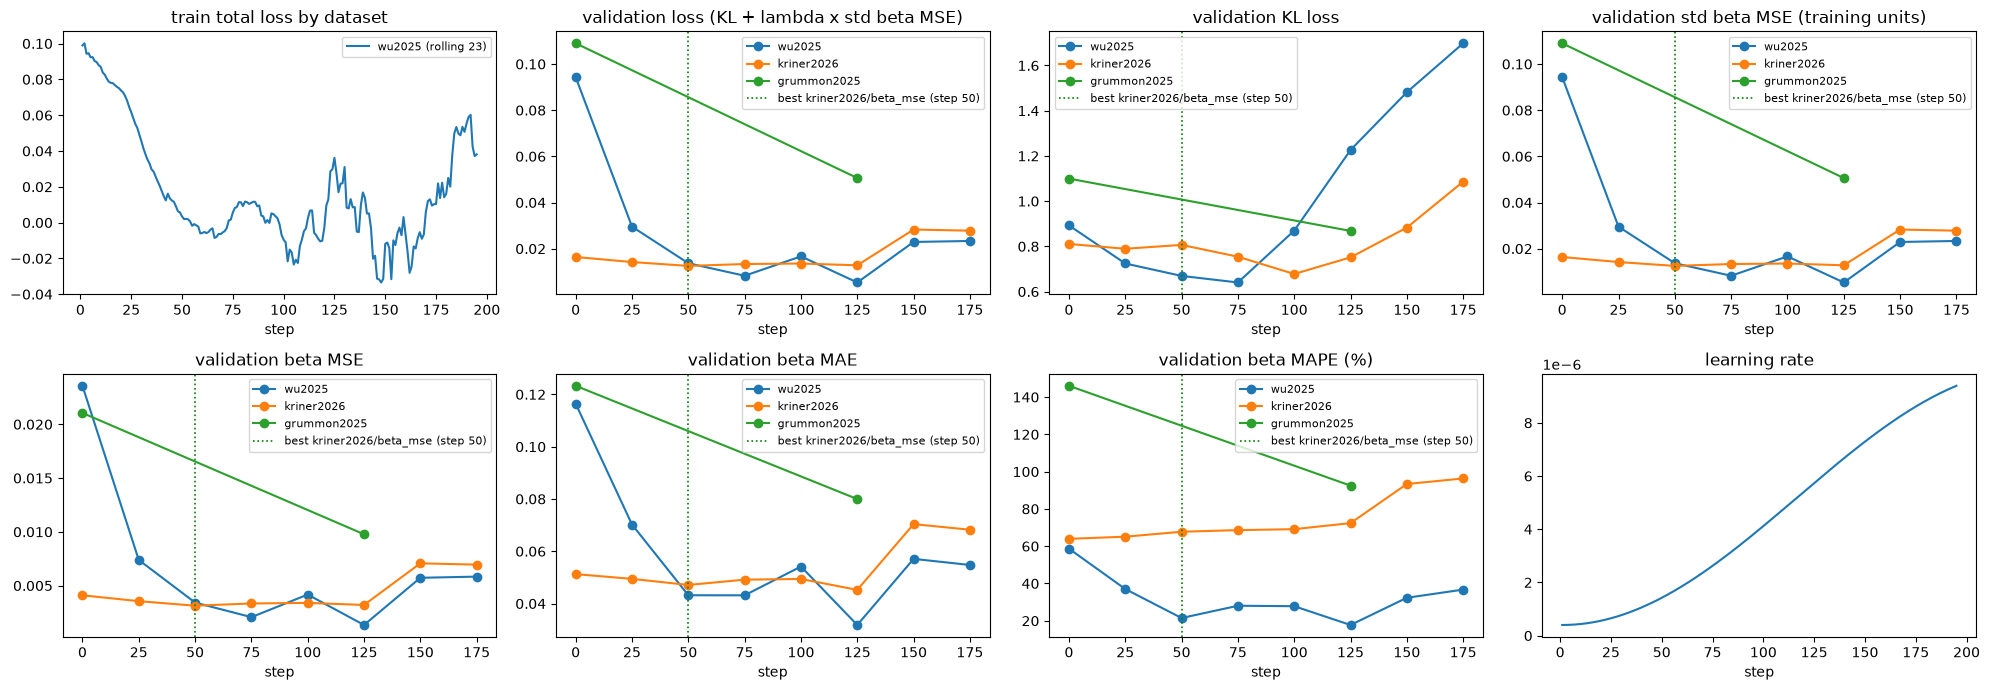

KeyboardInterrupt: 

In [12]:
# Beta-only run: the gradient is the split-sample cross loss alone (Wu inputs, Wu population betas as targets, no y)
beta_only_config = PopulationTrainConfig(
    train_datasets=tuple(TRAIN_DATASETS),
    sample_size_by_dataset={dataset_name: SAMPLE_SIZE for dataset_name in TRAIN_DATASETS},
    lr=PEAK_LR,
    num_epochs=NUM_EPOCHS,
    eval_every_by_validator=EVAL_EVERY_BY_VALIDATOR,
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MICRO_CHUNK,
    p0_chunk=P0_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
display(pd.Series(beta_only_config.as_dict(), name="beta_only_config").to_frame())
beta_only_run_dir = RUNS_DIR / f"beta_only_split_lr={PEAK_LR:g}_S={SAMPLE_SIZE}_ep={NUM_EPOCHS}"
runs["beta_only"] = run_population_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    target_std_betas_by_dataset=target_std_betas_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=beta_only_config,
    device=device,
    run_dir=beta_only_run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=from_scratch,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

# Held-out: base model vs beta-only best.pt

In [11]:
# Held-out datasets: Kriner 2026, Grummon 2025, Berke 2023 (whole dataset, all four vendor regressions); one fused
# validator each, with the same inference budgets as the Wu validator
from beta_train.model_state import reset_trainable
from beta_train.progress import PROGRESS_INTERVAL_SEC, HtmlProgress
from beta_train.runs import load_best, standardized_beta_mse
from beta_train.validation import validate_all

HELD_OUT_DATASETS = [
    "kriner2026",
    "grummon2025",
    "berke2023",
]

held_out_validators = {}
for dataset_name in HELD_OUT_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    held_out_choice_df = dataset_module.load_choice_df()
    held_out_rows = dataset_module.regression_rows(held_out_choice_df)
    held_out_specs = dataset_module.regression_specs(held_out_rows)
    held_out_validators[dataset_name] = PopulationValidator(
        dataset_module,
        held_out_choice_df,
        held_out_specs,
        max_questions=VALIDATION_MAX_QUESTIONS,
        max_chars=VALIDATION_MAX_CHARS,
    )
display(pd.DataFrame([validator.describe() for validator in held_out_validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,graph_limits,prep_sec
validator,,,,,,,,
kriner2026,fused,5000,990,kriner2026,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",0.778
grummon2025,fused,33798,4906,grummon2025,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",7.074
berke2023,fused,36297,1881,"berke2023/v0, berke2023/v1, berke2023/v2, berk...",1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",4.319


In [12]:
# Validate the base model (snapshot weights; loaded from the step-0 disk cache when it already ran) and the beta-only
# run's best.pt on every held-out dataset; the model is put back to the snapshot weights afterwards
base_held_out_validation, base_held_out_cache_report = validate_all_cached(
    kev_model,
    held_out_validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(base_held_out_cache_report)

best_checkpoint = load_best(beta_only_run_dir)
print(f"beta-only best.pt: {best_checkpoint['best']}")
reset_trainable(kev_model, best_checkpoint["trainable"])
held_out_bar = HtmlProgress(
    total=0, initial=0, description="held-out validation (waiting)", unit="batch", min_interval_sec=PROGRESS_INTERVAL_SEC
)
best_held_out_validation = validate_all(kev_model, held_out_validators, held_out_bar)
held_out_bar.close()
reset_trainable(kev_model, INIT_TRAINABLE_STATE)

,source
validator,
kriner2026,computed
grummon2025,computed
berke2023,computed


beta-only best.pt: {'metric': 'wu2025/beta_mse', 'mode': 'min', 'step': 80, 'value': 0.0007200125806129045}


In [13]:
# Per held-out dataset: KL, beta MSE, std beta MSE, MAE, Spearman rho for the base model and the beta-only best.pt
held_out_validations = {
    "base": base_held_out_validation,
    "beta_only_best": best_held_out_validation,
}
held_out_metric_rows = []
for dataset_name in HELD_OUT_DATASETS:
    for model_label, validation in held_out_validations.items():
        metrics, beta_df = validation[dataset_name]
        held_out_metric_rows.append({
            "validator": dataset_name,
            "model": model_label,
            "kl_loss": metrics["kl_loss"],
            "beta_mse": metrics["beta_mse"],
            "std_beta_mse": standardized_beta_mse(held_out_validators[dataset_name], beta_df),
            "beta_mae": metrics["beta_mae"],
            "spearman_rho": metrics["spearman_rho"],
        })
display(pd.DataFrame(held_out_metric_rows).set_index(["validator", "model"]).round(5))

kl_loss  beta_mse  std_beta_mse  beta_mae  spearman_rho
validator   model                                                                  
kriner2026  base            1.08483   0.01775       0.07099   0.11425      -0.26573
            beta_only_best  0.90933   0.00954       0.03814   0.08565       0.23776
grummon2025 base            1.05890   0.00546       0.02828   0.06510       0.50000
            beta_only_best  0.95257   0.00495       0.02564   0.05494       0.60000
berke2023   base            0.81868   0.11857       0.47429   0.29709      -0.34100
            beta_only_best  0.83577   0.10945       0.43780   0.28444      -0.14395

In [14]:
# Per held-out dataset: human population betas next to the base model's and the beta-only best.pt's
for dataset_name in HELD_OUT_DATASETS:
    base_beta_df = base_held_out_validation[dataset_name][1]
    best_beta_df = best_held_out_validation[dataset_name][1]
    if not base_beta_df.index.equals(best_beta_df.index):
        raise ValueError(f"{dataset_name}: base and best.pt beta tables have different terms")
    beta_table = pd.DataFrame(
        {
            "regression": base_beta_df["model"],
            "human_pop_beta": base_beta_df["human_pop_beta"],
            "base": base_beta_df["model_pop_beta"],
            "beta_only_best": best_beta_df["model_pop_beta"],
        },
        index=base_beta_df.index,
    )
    print(dataset_name)
    display(beta_table.round(4))

kriner2026


,regression,human_pop_beta,base,beta_only_best
term,,,,
Airline: Frontier,kriner2026,-0.0854,0.0343,0.0057
Airline: Southwest,kriner2026,-0.0238,0.0266,0.0100
Airline: United,kriner2026,-0.0220,0.0010,-0.0069
Fuel: Sustainable aviation fuel,kriner2026,0.0691,-0.0574,-0.0372
Baggage: Checked bag+carry-on,kriner2026,0.0561,-0.0434,-0.0341
Baggage: Personal item only,kriner2026,-0.1393,-0.0030,-0.0125
Space: Extra legroom,kriner2026,0.0653,-0.0813,-0.0113
Seat: Middle,kriner2026,-0.0906,-0.0058,-0.0053
Seat: Window,kriner2026,0.0384,0.0085,0.0134


grummon2025


,regression,human_pop_beta,base,beta_only_best
term,,,,
NutritionInfo vs Positive,grummon2025,0.1844,0.1280,0.1078
HighIn vs Positive,grummon2025,0.0541,0.1227,0.0538
Positive+NutritionInfo vs Positive,grummon2025,0.1788,0.1573,0.1248
Positive+HighIn vs Positive,grummon2025,0.1194,-0.0085,-0.0055
Spectrum vs Positive,grummon2025,0.1083,0.0573,0.0897


berke2023


,regression,human_pop_beta,base,beta_only_best
term,,,,
v0: take-out food | Drone privacy: YES vs NO,berke2023/v0,0.1607,-0.2362,-0.2806
v0: take-out food | Fee L1 vs $0 ($1),berke2023/v0,-0.1509,-0.0218,-0.0272
v0: take-out food | Fee L2 vs $0 ($3 fast / $5 meds),berke2023/v0,-0.3298,-0.0141,-0.0204
v0: take-out food | Fee L3 vs $0 ($5 fast / $10 meds),berke2023/v0,-0.4978,0.0002,-0.0182
v0: take-out food | Wait L1 vs L0 (20m fast / 2h meds),berke2023/v0,-0.0631,0.0024,-0.0051
v0: take-out food | Wait L2 vs L0 (30m fast / 6h meds),berke2023/v0,-0.2082,0.0211,0.0024
v0: take-out food | Wait L3 vs L0 (45m fast / 1d meds),berke2023/v0,-0.3419,0.0371,0.0018
v1: prescription medications | Drone privacy: YES vs NO,berke2023/v1,0.2242,-0.3136,-0.2894
v1: prescription medications | Fee L1 vs $0 ($1),berke2023/v1,-0.0822,-0.0243,-0.0268
